# Competing Platforms in Mobile Crowdsensing: D1 simulation (full setup)

Abdullah Sajid, Mishal Sagar (LUMS, EE567/CS6315 Multiagent Systems)

This notebook runs the setup described in the proposal:

| Proposal item | Implemented as |
|-|-|
| Real Beijing mobility traces | T-Drive taxis (one week, Feb 2008) and GeoLife walking segments, on a 500 m grid over central Beijing |
| Several hundred users | 200 taxi drivers + 100 pedestrians |
| 2 to 4 platforms | 4 apps (air quality, traffic, noise, weather); experiments use M = 2, 3, 4 |
| Budgets | an hourly budget per app; tasks are posted only while the budget allows |
| Three user types | honest, loyal (20%), strategic (0 / 25 / 50%) |
| Payment inequality, task completion | Gini of user earnings; share of posted tasks completed |
| Mesa | `crowdsim/mesa_model.py`: `UserAgent`, `PlatformAgent`, `CrowdsensingModel(mesa.Model)` |
| Three core methods | fixed posted price, Q-learning pricing, rival-offer learning |

Mathematical formulation: `formulation.md`. Every modelling assumption: `assumptions.md`.

Heavy runs are parallelised over 8 cores and cached in `results/full/`; delete that folder to recompute.

**Running in Google Colab:** run the next cell first. It clones the repository, which holds the code, the processed Beijing week and cached results, and installs Mesa. Cached results load in about a minute. To recompute everything, delete `results/full/` (about 40 min on Colab's 2 cores).

In [ ]:
# --- Colab setup (skipped when running locally) ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("crowdsim"):
    if not os.path.exists("competing-platforms-crowdsensing"):
        !git clone -q https://github.com/abdullahsajidfr/competing-platforms-crowdsensing.git
    %cd competing-platforms-crowdsensing
    !pip -q install "mesa>=3.1"


In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from crowdsim.mesa_model import City, CrowdsensingModel, gini
import crowdsim.full_experiments as fx
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
T0 = time.time()
city = fx.city()
SEEDS = range(10)
B_TIGHT, B_BASE, B_LOOSE = 150.0, 300.0, 600.0          # hourly budget per app (calibrated in assumptions.md)
WEEK = 168
print(f"grid {city.rows}x{city.cols} = {city.G} cells of 500 m;  users: {len(city.users)} "
      f"({sum(u['kind']=='taxi' for u in city.users)} taxis, {sum(u['kind']=='ped' for u in city.users)} pedestrians)")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


grid 36x38 = 1368 cells of 500 m;  users: 300 (200 taxis, 100 pedestrians)


## 1. The data: Beijing, one replayed week

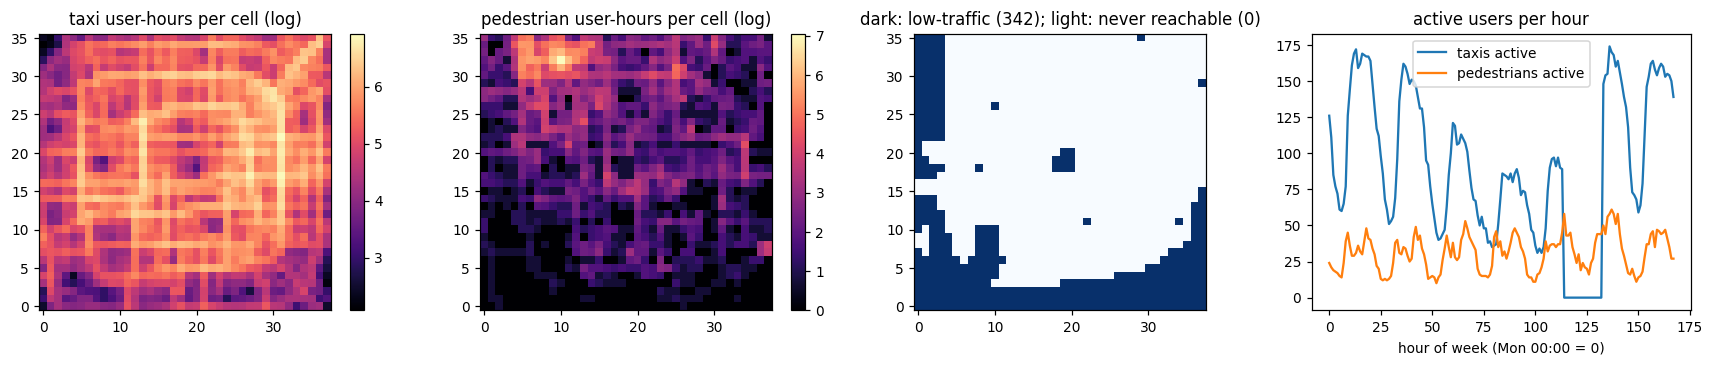

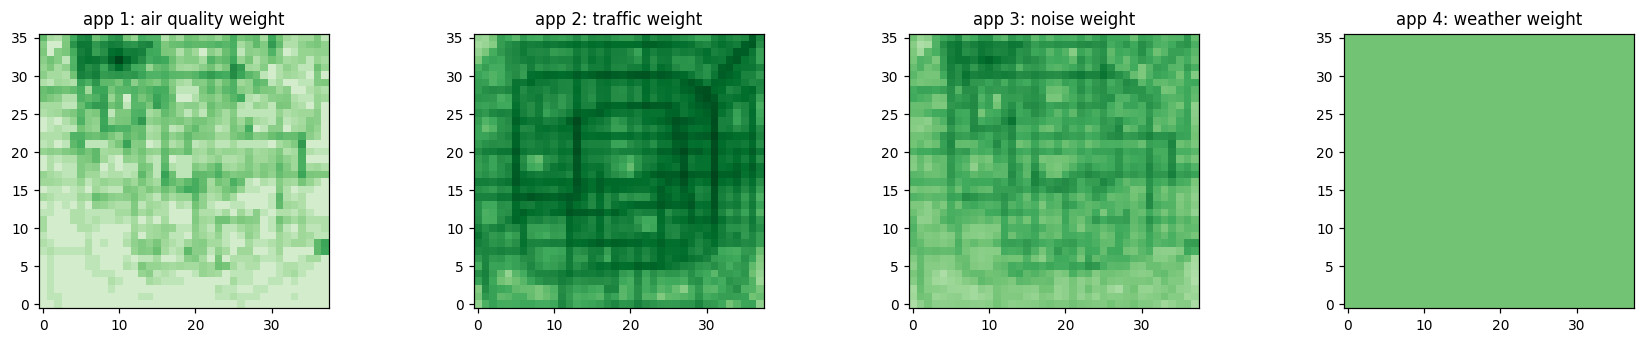

active users per hour: mean 121, min 16, max 232


In [2]:
act = np.array([[len(r) > 0 for r in u["routes"]] for u in city.users])
kinds = np.array([u["kind"] for u in city.users])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for k, (v, t) in enumerate([(np.log1p(city.taxi_visits), "taxi user-hours per cell (log)"), (np.log1p(city.ped_visits), "pedestrian user-hours per cell (log)")]):
    im = ax[k].imshow(v.reshape(city.rows, city.cols), origin="lower", cmap="magma"); ax[k].set_title(t); plt.colorbar(im, ax=ax[k], fraction=.046)
ax[2].imshow((city.low_traffic * 2 + ~city.reachable_ever).reshape(city.rows, city.cols), origin="lower", cmap="Blues", vmin=0, vmax=2)
ax[2].set_title(f"dark: low-traffic ({city.low_traffic.sum()}); light: never reachable ({(~city.reachable_ever).sum()})")
ax[3].plot(act[kinds == "taxi"].sum(0), label="taxis active"); ax[3].plot(act[kinds == "ped"].sum(0), label="pedestrians active")
ax[3].set(xlabel="hour of week (Mon 00:00 = 0)", title="active users per hour"); ax[3].legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for j in range(4):
    im = ax[j].imshow(city.W_all[j].reshape(city.rows, city.cols), origin="lower", cmap="Greens", vmin=0, vmax=1)
    ax[j].set_title(f"app {j+1}: {city.app_names[j]} weight")
plt.tight_layout(); plt.show()
print(f"active users per hour: mean {act.sum(0).mean():.0f}, min {act.sum(0).min()}, max {act.sum(0).max()}")

## 2. Check: users really reach a Nash equilibrium every hour
For one week at the base budget, after each hour's best-response dynamics, we test every active user's every alternative task. Proposition 1 says this must always succeed.

In [3]:
m = CrowdsensingModel(city, M=2, mechanism="fixed", budget=B_BASE, seed=0)
viol = 0; sweeps = []
for h in range(WEEK):
    m.stage(h); sweeps.append(m.sweeps)
    for u in m.users:
        if not u.active or len(u.aj) == 0: continue
        k = u.choice
        if k >= 0: m.n[u.aj[k], u.ag[k]] -= 1
        util = m.R[u.aj, u.ag] / (m.n[u.aj, u.ag] + 1) - u.ac
        cur = 0.0 if k < 0 else util[k]
        if max(util.max(), 0) > cur + 1e-9: viol += 1
        if k >= 0: m.n[u.aj[k], u.ag[k]] += 1
print(f"168 hours checked: users who could still gain by switching = {viol};  best-response sweeps per hour: mean {np.mean(sweeps):.1f}, max {max(sweeps)}")

168 hours checked: users who could still gain by switching = 0;  best-response sweeps per hour: mean 3.3, max 5


## 3. Experiment 1: baseline (fixed posted price, m = 1)
Settings: M = 2, 3, 4 apps × three budgets × 10 seeds × 2 weeks. No learning.

Seeds change user costs and who is loyal; routes are the real traces.

In [4]:
cfgs = [dict(M=M, mechanism="fixed", m=1.0, budget=B) for M in (2, 3, 4) for B in (B_TIGHT, B_BASE, B_LOOSE)]
E1 = fx.cached("E1_baseline", fx.run_grid, cfgs, SEEDS, 2 * WEEK, 0)
e1 = pd.DataFrame([dict(M=r["kw"]["M"], budget=r["kw"]["budget"], **r["summary"]) for r in E1])
cols = ["coverage", "low_cov", "spend_total", "profit_total", "task_completion", "participation", "user_net_per_active_hour", "gini_all", "cells_per_100"]
display(e1.groupby(["M", "budget"])[cols].mean())

[E1_baseline] 42s


coverage  low_cov  spend_total  profit_total  task_completion  participation  user_net_per_active_hour  gini_all  cells_per_100
M budget                                                                                                                                 
2 150.0      0.037    0.000      224.707       268.995            0.740          0.493                     0.836     0.440         22.496
  300.0      0.058    0.002      352.253       377.071            0.554          0.712                     1.403     0.371         22.662
  600.0      0.074    0.003      450.628       455.681            0.330          0.856                     1.899     0.329         22.355
3 150.0      0.035    0.000      259.225       292.710            0.561          0.541                     1.022     0.415         18.473
  300.0      0.055    0.002      390.977       402.972            0.404          0.761                     1.617     0.350         19.354
  600.0      0.068    0.003      464.322       466.660            0.225          0.870                     1.996     0.315         19.997
4 150.0      0.040    0.018      274.963       305.981            0.395          0.588                     1.064     0.406         19.712
  300.0      0.060    0.019      407.472       416.862            0.282          0.812                     1.661     0.346         20.256
  600.0      0.073    0.015      479.802       480.404            0.159          0.918                     2.037     0.315         20.718

## 4. Experiment 2 (RQ2): do learning platforms raise or lower payments?
**Step 1: stage-game benchmarks.** For every price profile on the grid, the users' equilibrium is computed for all 168 hours, using the Mesa model with fixed prices. This gives:
- each app's expected profit;
- the static Nash prices (competitive);
- the joint-profit prices (collusive).

**Step 2: Q-learning.** Q-learners (state = last round's prices of all apps) run for up to $10^6$ hours, replaying the week, with 10 seeds.

**Controls:**
- *myopic* ($\gamma=0$);
- *memoryless* (can't condition on rivals' prices, so can't punish).

In [5]:
GRIDS = {2: np.round(np.arange(0.4, 1.61, 0.2), 2), 3: np.array([0.6, 0.8, 1.0, 1.2, 1.4]), 4: np.array([0.6, 0.9, 1.2, 1.5])}
banks, bms = {}, {}
for M in (2, 3, 4):
    banks[M] = fx.cached(f"E2_bank_M{M}", fx.build_bank, M, GRIDS[M], B_BASE)
    bms[M] = fx.benchmarks(banks[M])
    print(f"M={M}: grid {list(GRIDS[M])}; {bms[M]}")

[E2_bank_M2] 12s
M=2: grid [np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0), np.float64(1.2), np.float64(1.4), np.float64(1.6)]; {'collusive': (np.float64(0.8), np.float64(0.6)), 'pi_C': 491.471707208299, 'nash_type': 'mixed', 'nash_m': (0.9870259171036504, 0.6521797214458366), 'pi_N': 451.48963832442223, 'mixed': ({0.8: 0.06, 1.0: 0.94}, {0.6: 0.74, 0.8: 0.26})}


[E2_bank_M3] 30s
M=3: grid [np.float64(0.6), np.float64(0.8), np.float64(1.0), np.float64(1.2), np.float64(1.4)]; {'collusive': (np.float64(0.8), np.float64(0.6), np.float64(0.6)), 'pi_C': 505.454408041653, 'nash_type': 'none (no pure NE; mixed NE not computed for M>2)', 'pi_N': nan}


[E2_bank_M4] 64s
M=4: grid [np.float64(0.6), np.float64(0.9), np.float64(1.2), np.float64(1.5)]; {'collusive': (np.float64(0.6), np.float64(0.6), np.float64(0.6), np.float64(0.9)), 'pi_C': 514.4242906328088, 'nash_type': 'none (no pure NE; mixed NE not computed for M>2)', 'pi_N': nan}


In [6]:
Q = {}
for M in (2, 3, 4):
    Q[(M, "Q-learning")] = fx.cached(f"E2_q_M{M}", fx.run_q, banks[M], SEEDS)
    Q[(M, "myopic γ=0")] = fx.cached(f"E2_q_M{M}_myopic", fx.run_q, banks[M], SEEDS, gamma=0.0)
    Q[(M, "memoryless")] = fx.cached(f"E2_q_M{M}_nomem", fx.run_q, banks[M], SEEDS, memory=False)
rows = []
for (M, lab), runs in Q.items():
    bk, bm = banks[M], bms[M]
    for r in runs:
        lo = fx.limit_outcome(r, bk)
        start = bk["grid"][r["trace"][:25, 1:]].mean()          # average price level in the first 50k hours
        rows.append(dict(M=M, setting=lab, seed=r["seed"], converged=r["converged"], hours=r["t_end"],
                         m_start=start, m_end=lo["m"].mean(), joint=lo["joint"], spend=lo["spend"], usernet=lo["usernet"],
                         coverage=lo["coverage"], completion=lo["completion"],
                         Delta=(lo["joint"] - bm["pi_N"]) / (bm["pi_C"] - bm["pi_N"]) if np.isfinite(bm["pi_N"]) else np.nan))
E2 = pd.DataFrame(rows)
# competitive reference that exists for every M: the myopic learners' joint profit
my = E2[E2.setting == "myopic γ=0"].groupby("M").joint.mean()
E2["Delta_vs_myopic"] = [(r.joint - my[r.M]) / (bms[r.M]["pi_C"] - my[r.M]) for r in E2.itertuples()]
summ = E2.groupby(["M", "setting"])[["converged", "hours", "m_start", "m_end", "joint", "spend", "usernet", "coverage", "Delta", "Delta_vs_myopic"]].mean()
ref = pd.DataFrame([dict(M=M, setting=f"benchmark: Nash ({bms[M]['nash_type'].split()[0]})", m_end=np.mean(bms[M].get("nash_m", [np.nan])), joint=bms[M]["pi_N"], Delta=0.0) for M in (2, 3, 4)] +
                   [dict(M=M, setting="benchmark: collusive", m_end=np.mean(bms[M]["collusive"]), joint=bms[M]["pi_C"], Delta=1.0) for M in (2, 3, 4)]).set_index(["M", "setting"])
display(pd.concat([summ, ref]).sort_index())

[E2_q_M2] 9s


[E2_q_M2_myopic] 10s


[E2_q_M2_nomem] 8s


[E2_q_M3] 17s


[E2_q_M3_myopic] 16s


[E2_q_M3_nomem] 12s


[E2_q_M4] 19s


[E2_q_M4_myopic] 24s


[E2_q_M4_nomem] 17s


converged      hours  m_start  m_end    joint    spend  usernet  coverage  Delta  Delta_vs_myopic
M setting                                                                                                                   
2 Q-learning                     1.0  8.158e+05    0.942  0.752  474.706  271.753   92.158     0.061  0.581        5.882e-01
  benchmark: Nash (mixed)        NaN        NaN      NaN  0.820  451.490      NaN      NaN       NaN  0.000              NaN
  benchmark: collusive           NaN        NaN      NaN  0.700  491.472      NaN      NaN       NaN  1.000              NaN
  memoryless                     1.0  6.583e+05    0.958  0.700  491.472  248.813   74.115     0.061  1.000        1.000e+00
  myopic γ=0                     1.0  8.895e+05    0.940  0.825  450.758  301.228  116.617     0.061 -0.018        1.388e-15
3 Q-learning                     1.0  8.951e+05    0.981  0.985  405.364  384.602  183.098     0.058    NaN        3.162e-01
  benchmark: Nash (none)         NaN        NaN      NaN    NaN      NaN      NaN      NaN       NaN  0.000              NaN
  benchmark: collusive           NaN        NaN      NaN  0.667  505.454      NaN      NaN       NaN  1.000              NaN
  memoryless                     1.0  8.162e+05    0.994  1.040  391.251  397.601  194.148     0.058    NaN        2.198e-01
  myopic γ=0                     1.0  1.031e+06    0.982  1.168  359.084  409.340  213.750     0.053    NaN        3.886e-17
4 Q-learning                     1.0  9.497e+05    1.056  1.006  410.714  391.973  180.696     0.062    NaN        4.088e-01
  benchmark: Nash (none)         NaN        NaN      NaN    NaN      NaN      NaN      NaN       NaN  0.000              NaN
  benchmark: collusive           NaN        NaN      NaN  0.675  514.424      NaN      NaN       NaN  1.000              NaN
  memoryless                     1.0  7.632e+05    1.061  0.990  448.249  385.732  170.177     0.062    NaN        6.227e-01
  myopic γ=0                     1.0  1.162e+06    1.057  1.226  339.015  444.567  236.515     0.057    NaN       -3.331e-17

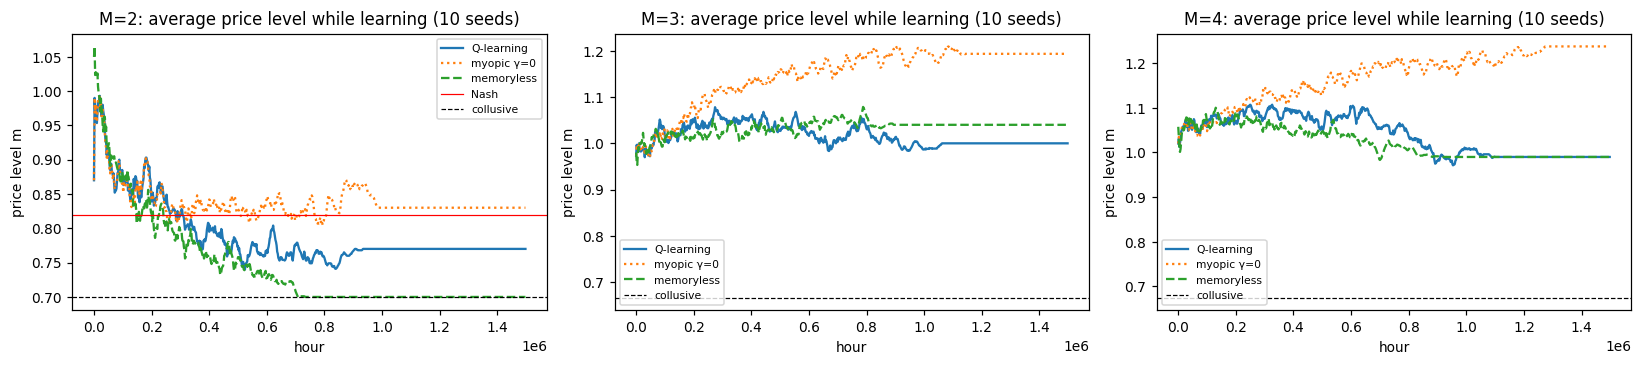

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for k, M in enumerate((2, 3, 4)):
    for lab, ls in [("Q-learning", "-"), ("myopic γ=0", ":"), ("memoryless", "--")]:
        L = 750                                                  # 1.5M hours / 2000 per record
        def pad(r):
            x = banks[M]["grid"][r["trace"][:, 1:]].mean(1)          # learning ends early -> hold last value
            return np.concatenate([x, np.full(max(0, L - len(x)), x[-1])])[:L]
        tr = np.mean([pad(r) for r in Q[(M, lab)]], 0)
        ax[k].plot(np.arange(L) * 2000, pd.Series(tr).rolling(10, min_periods=1).mean(), ls, label=lab)
    if "nash_m" in bms[M]: ax[k].axhline(np.mean(bms[M]["nash_m"]), c="r", lw=.8, label="Nash")
    ax[k].axhline(np.mean(bms[M]["collusive"]), c="k", ls="--", lw=.8, label="collusive")
    ax[k].set(title=f"M={M}: average price level while learning (10 seeds)", xlabel="hour", ylabel="price level m"); ax[k].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Experiment 3 (RQ1): do false rival offers raise user earnings or platform spending?
All apps use rival-offer learning. Strategic users report $(1+\delta)$ × the pay they actually got.

Runs share routes, costs and seeds; the strategic sets are nested, so we follow **the same people**:
- **A**: strategic at both 25% and 50%;
- **B**: strategic at 50% only;
- **C**: honest throughout;
- **L**: loyal.

Each run lasts 5 weeks; the first 2 weeks are burn-in.

In [8]:
T3, BURN3 = 5 * WEEK, 2 * WEEK
grid3 = []
for M in (2, 3, 4):
    for sh in (0.0, 0.25, 0.5):
        grid3.append(dict(M=M, mechanism="rival", budget=B_BASE, strategic_share=sh, delta=0.5))
for sh in (0.25, 0.5):
    grid3.append(dict(M=2, mechanism="rival", budget=B_BASE, strategic_share=sh, delta=1.0))
for B in (B_TIGHT, B_LOOSE):
    for sh in (0.0, 0.5):
        grid3.append(dict(M=2, mechanism="rival", budget=B, strategic_share=sh, delta=0.5))
for sh in (0.0, 0.5):
    grid3.append(dict(M=2, mechanism="rival", budget=B_BASE, strategic_share=sh, delta=0.5, update="max"))
E3 = fx.cached("E3_lying", fx.run_grid, grid3, SEEDS, T3, BURN3, True)
def key(kw): return (kw["M"], kw["budget"], kw.get("delta", 0.5), kw.get("update", "avg"))
runs3 = {}
for r in E3: runs3.setdefault(key(r["kw"]), {})[(r["kw"]["strategic_share"], r["kw"]["seed"])] = r
rows = []
for k, d in runs3.items():
    base_d = runs3.get((k[0], k[1], 0.5, k[3]), {})          # 0% liars: delta is irrelevant
    for s in SEEDS:
        if (0.0, s) not in base_d: continue
        b0 = base_d[(0.0, s)]; ut0 = b0["utype"]
        for sh in (0.25, 0.5):
            if (sh, s) not in d: continue
            r = d[(sh, s)]
            A = d[(0.25, s)]["utype"] == "strategic" if (0.25, s) in d else None
            S50 = d[(0.5, s)]["utype"] == "strategic" if (0.5, s) in d else r["utype"] == "strategic"
            C = (ut0 == "honest") & ~S50; L = ut0 == "loyal"
            row = dict(M=k[0], budget=k[1], delta=k[2], upd=k[3], share=sh, seed=s)
            for met in ("spend_total", "profit_total", "coverage", "low_cov", "gini_all", "task_completion", "user_net_per_active_hour"):
                row[met] = 100 * (r["summary"][met] - b0["summary"][met]) / abs(b0["summary"][met]) if b0["summary"][met] else np.nan
            grp = {"C (honest)": C, "L (loyal)": L}
            if A is not None: grp["A (liar 25%+50%)"] = A
            if A is not None: grp["B (liar 50% only)"] = S50 & ~A
            else: grp["liars"] = S50
            for g, mask in grp.items():
                row[f"earn {g}"] = 100 * (r["earn"][mask].mean() - b0["earn"][mask].mean()) / b0["earn"][mask].mean()
            rows.append(row)
CH3 = pd.DataFrame(rows)
print("% change vs the 0%-liar run with the same seed (mean over 10 seeds); main setting first")
main = CH3[(CH3.budget == B_BASE) & (CH3.delta == 0.5) & (CH3.upd == "avg")]
display(main.groupby(["M", "share"]).mean(numeric_only=True).drop(columns=["budget", "delta", "seed"]).T)

[E3_lying] 280s
% change vs the 0%-liar run with the same seed (mean over 10 seeds); main setting first


M                              2               3              4        
share                       0.25    0.50    0.25    0.50   0.25    0.50
spend_total                3.214   5.082   3.165   4.171  3.024   4.102
profit_total              -3.973  -6.850  -7.067 -10.187 -7.724 -11.594
coverage                  -2.289  -4.030  -2.752  -4.226 -2.524  -3.947
low_cov                  -24.490 -31.974  37.667 -11.833 -0.421  -0.472
gini_all                  -0.627  -0.203  -1.002  -1.186 -0.764  -0.928
task_completion            1.838   2.704   1.291   1.427  0.630   0.582
user_net_per_active_hour   7.396  11.925   4.821   6.452  4.573   6.342
earn C (honest)            7.253  11.332   4.951   6.695  4.637   6.380
earn L (loyal)             6.327  10.784   4.324   5.901  4.326   5.948
earn A (liar 25%+50%)      9.153  12.821   5.311   6.683  4.954   6.567
earn B (liar 50% only)     6.708  12.672   4.692   6.529  4.391   6.531
earn liars                   NaN     NaN     NaN     NaN    NaN     NaN

Sensitivity (M=2, 50% liars): bigger lie, budgets, PACMAB max update


budget                   150.0   300.0                 600.0
delta                      0.5     0.5            1.0    0.5
upd                        avg     avg    max     avg    avg
spend_total              4.321   5.082  2.580   6.808  3.070
profit_total            -3.095  -6.850 -5.612  -9.682 -6.873
coverage                -2.157  -4.030 -2.856  -5.701 -0.843
gini_all                -4.170  -0.203  0.759  -0.035  0.929
earn C (honest)         10.813  11.332  6.437  15.377  4.533
earn L (loyal)          11.988  10.784  5.523  14.326  4.906
earn A (liar 25%+50%)      NaN  12.821    NaN  16.619    NaN
earn B (liar 50% only)     NaN  12.672    NaN  15.921    NaN
earn liars              11.337     NaN  5.925     NaN  4.996

seeds with spending up  seeds with honest earnings up
M share                                                       
2 0.25                       10                             10
  0.50                       10                             10
3 0.25                       10                             10
  0.50                       10                             10
4 0.25                       10                             10
  0.50                       10                             10

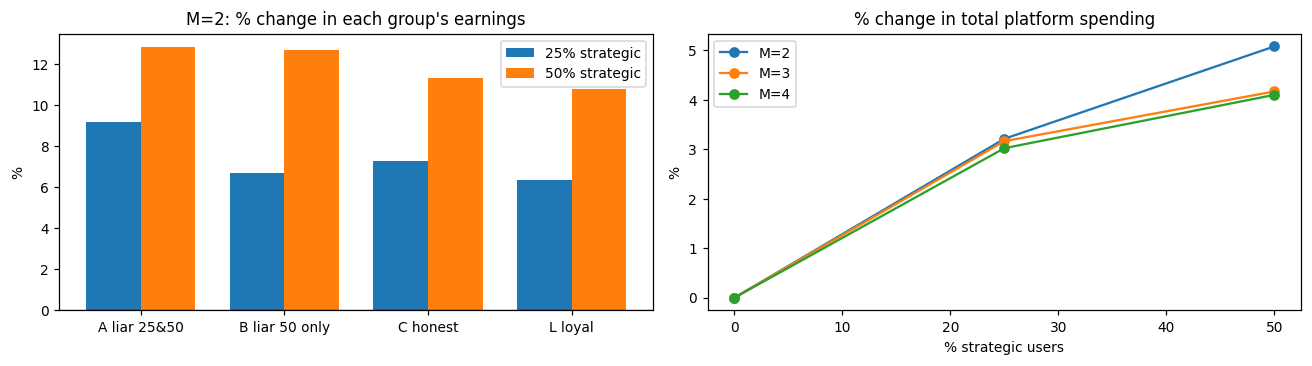

In [9]:
print("Sensitivity (M=2, 50% liars): bigger lie, budgets, PACMAB max update")
sens = CH3[(CH3.M == 2) & (CH3.share == 0.5)].groupby(["budget", "delta", "upd"]).mean(numeric_only=True)
display(sens[["spend_total", "profit_total", "coverage", "gini_all"] + [c for c in sens.columns if c.startswith("earn")]].T)
sign = pd.DataFrame({"seeds with spending up": main.groupby(["M", "share"]).spend_total.apply(lambda x: int((x > 0).sum())),
                     "seeds with honest earnings up": main.groupby(["M", "share"])["earn C (honest)"].apply(lambda x: int((x > 0).sum()))})
display(sign)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
m2 = main[main.M == 2].groupby("share").mean(numeric_only=True)
grps = ["earn A (liar 25%+50%)", "earn B (liar 50% only)", "earn C (honest)", "earn L (loyal)"]
for k, sh in enumerate((0.25, 0.5)):
    ax[0].bar(np.arange(4) + 0.38 * k, m2.loc[sh, grps], 0.38, label=f"{int(sh*100)}% strategic")
ax[0].set_xticks(np.arange(4) + 0.19); ax[0].set_xticklabels(["A liar 25&50", "B liar 50 only", "C honest", "L loyal"])
ax[0].axhline(0, c="k", lw=.8); ax[0].set(title="M=2: % change in each group's earnings", ylabel="%"); ax[0].legend()
for M in (2, 3, 4):
    mm = main[main.M == M].groupby("share").spend_total.mean()
    ax[1].plot([0] + [int(100 * s) for s in mm.index], [0] + list(mm.values), "o-", label=f"M={M}")
ax[1].set(title="% change in total platform spending", xlabel="% strategic users", ylabel="%"); ax[1].legend()
plt.tight_layout(); plt.show()

**Payment trend under rival-offer learning (RQ2, second learning method).**

Below is the average posted price level per hour with honest users only. Prices start at 1.0, the fixed-price level.

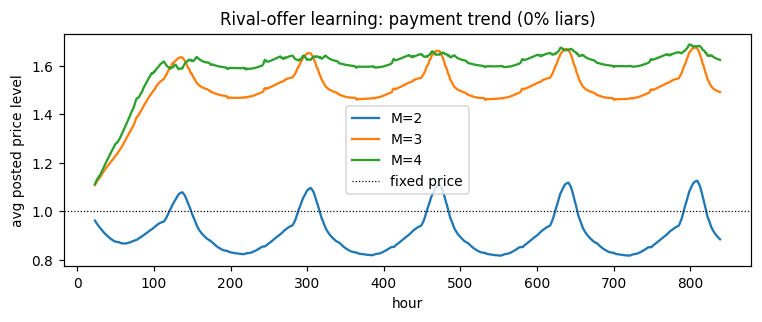

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
for M in (2, 3, 4):
    ts = np.mean([runs3[(M, B_BASE, 0.5, "avg")][(0.0, s)]["ts"][[f"m{j}" for j in range(M)]].mean(1).values for s in SEEDS], 0)
    ax.plot(pd.Series(ts).rolling(24).mean(), label=f"M={M}")
ax.axhline(1.0, c="k", ls=":", lw=.8, label="fixed price"); ax.set(xlabel="hour", ylabel="avg posted price level", title="Rival-offer learning: payment trend (0% liars)"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Experiment 4 (RQ3): are low-traffic areas left uncovered, and can a bonus help?
Setup: fixed price, M = 2, base budget. Each app reserves 25% of its budget for low-traffic cells and pays them a bonus of 0 to 300%.

The total budget is the same in every run.

[E4_bonus] 63s


,reachable_cov,low_cov,low_covered_cells,covered_cells,spend_total,profit_total,task_completion,gini_all
bonus,,,,,,,,
0.0,0.058,0.002,0.744,79.826,352.253,377.071,0.554,0.371
0.5,0.057,0.040,13.555,77.293,356.976,343.878,0.558,0.356
1.0,0.055,0.037,12.600,75.447,367.812,317.141,0.582,0.352
2.0,0.053,0.029,9.882,73.110,380.619,287.791,0.600,0.357
3.0,0.053,0.022,7.405,72.172,386.940,277.713,0.605,0.369


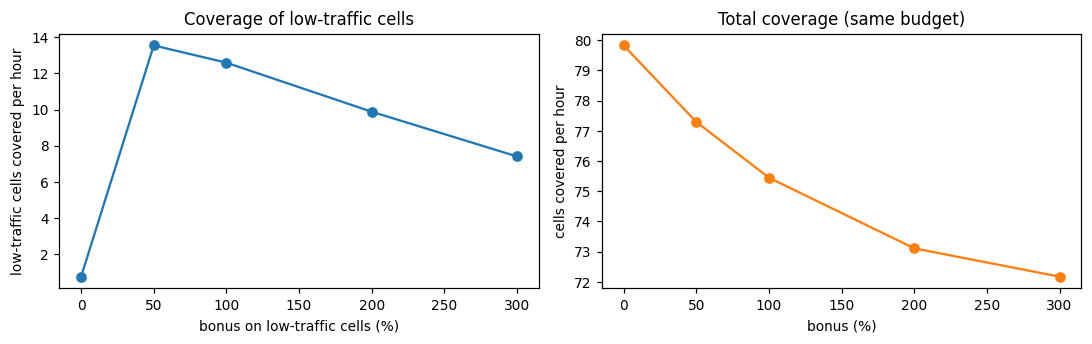

In [11]:
bon = [dict(M=2, mechanism="fixed", m=1.0, budget=B_BASE, bonus=bo, reserve=0.25 if bo > 0 else 0.0) for bo in (0.0, 0.5, 1.0, 2.0, 3.0)]
E4 = fx.cached("E4_bonus", fx.run_grid, bon, SEEDS, 2 * WEEK, 0)
e4 = pd.DataFrame([dict(bonus=r["kw"]["bonus"], **r["summary"]) for r in E4])
t4 = e4.groupby("bonus")[["reachable_cov", "low_cov", "low_covered_cells", "covered_cells", "spend_total", "profit_total", "task_completion", "gini_all"]].mean()
display(t4)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t4.index * 100, t4.low_covered_cells, "o-"); ax[0].set(xlabel="bonus on low-traffic cells (%)", ylabel="low-traffic cells covered per hour", title="Coverage of low-traffic cells")
ax[1].plot(t4.index * 100, t4.covered_cells, "o-", c="C1"); ax[1].set(xlabel="bonus (%)", ylabel="cells covered per hour", title="Total coverage (same budget)")
plt.tight_layout(); plt.show()

## 7. Experiment 5 (RQ4): which core method gives the best coverage per unit budget?
Setup: equal hourly budget for every app (base budget), honest and loyal users only, M = 2, 3, 4. The three methods:
- **fixed price** (m = 1), from Experiment 1;
- **Q-learning**: the learned strategies from Experiment 2, played inside the Mesa model for 2 weeks;
- **rival-offer learning**: Experiment 3 with 0% liars, after burn-in.

[E5_qeval_M2] 16s


[E5_qeval_M3] 8s


[E5_qeval_M4] 8s


reachable_cov  cells_per_100  low_cells_per_100  covered_cells  low_covered_cells  spend_total  profit_total  task_completion  gini_all  user_net_per_active_hour
M method                                                                                                                                                                        
2 Q-learning           0.062         30.980              0.200         84.433              0.549      274.051       480.178            0.432     0.447                     0.801
  fixed price          0.058         22.662              0.211         79.826              0.744      352.253       377.071            0.554     0.371                     1.403
  rival-offer          0.060         26.282              0.148         82.488              0.466      313.858       421.063            0.513     0.398                     1.085
3 Q-learning           0.058         20.677              0.083         79.437              0.319      384.720       406.063            0.388     0.354                     1.552
  fixed price          0.055         19.354              0.169         75.670              0.660      390.977       402.972            0.404     0.350                     1.617
  rival-offer          0.050         15.592              0.001         68.663              0.005      440.370       303.816            0.497     0.424                     2.165
4 Q-learning           0.063         21.918              2.166         86.012              8.489      393.915       414.234            0.277     0.352                     1.536
  fixed price          0.060         20.256              1.566         82.537              6.382      407.472       416.862            0.282     0.346                     1.661
  rival-offer          0.057         15.667              1.964         77.361              9.700      493.796       285.033            0.406     0.372                     2.432

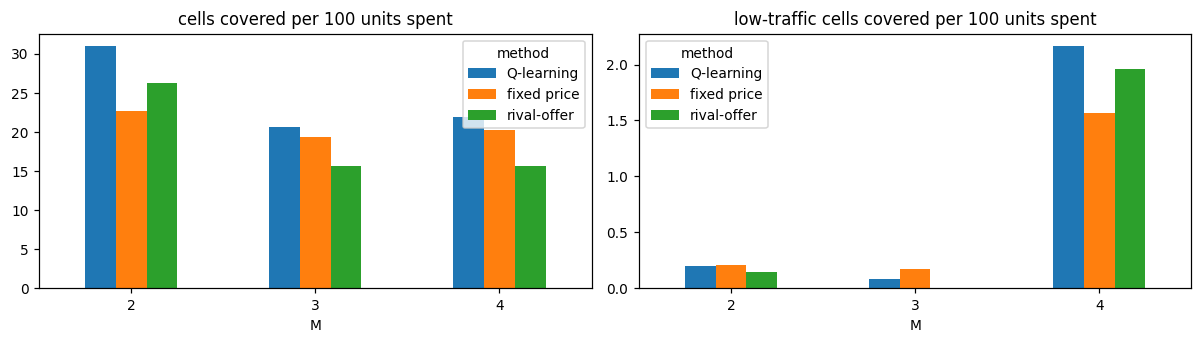

total runtime: 11.0 min


In [12]:
QE = {M: fx.cached(f"E5_qeval_M{M}", fx.eval_q, Q[(M, "Q-learning")], banks[M], B_BASE) for M in (2, 3, 4)}
rows = []
for r in E1:
    if r["kw"]["budget"] == B_BASE: rows.append(dict(M=r["kw"]["M"], method="fixed price", **r["summary"]))
for M in (2, 3, 4):
    for e in QE[M]: rows.append(dict(M=M, method="Q-learning", **e["summary"]))
    for s in SEEDS: rows.append(dict(M=M, method="rival-offer", **runs3[(M, B_BASE, 0.5, "avg")][(0.0, s)]["summary"]))
E5 = pd.DataFrame(rows)
cols5 = ["reachable_cov", "cells_per_100", "low_cells_per_100", "covered_cells", "low_covered_cells", "spend_total", "profit_total", "task_completion", "gini_all", "user_net_per_active_hour"]
t5 = E5.groupby(["M", "method"])[cols5].mean()
display(t5)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for k, met in enumerate(["cells_per_100", "low_cells_per_100"]):
    t5[met].unstack().plot.bar(ax=ax[k], rot=0); ax[k].set(title=["cells covered per 100 units spent", "low-traffic cells covered per 100 units spent"][k])
plt.tight_layout(); plt.show()
print(f"total runtime: {(time.time()-T0)/60:.1f} min")

## 8. Summary
The interpretation, per research question, is in `report.md`.